<a href="https://colab.research.google.com/github/<YOUR-GITHUB-USERNAME>/scikit-learn-cookbook/blob/main/02.%20Data%20Preprocessing/ch02_preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 2: Pre-Model Workflow and Data Preprocessing

Without question, the **quality of the data** is the most important factor in the success of an ML model. Training courses often skip this stage because it looks tedious compared with model training, but the old rule *"garbage in, garbage out"* applies without exception. Preprocessing is also not a one-off task: data keeps changing over time, so the same steps must be applied again and again to new data in production.

**What this notebook covers**

1. The impact of raw data on model performance (missing values, outliers, scale, categories, leakage)
2. **Handling missing data**: `SimpleImputer`, `KNNImputer`, `IterativeImputer`, and how to *measure* which one is better
3. **Scaling**: `StandardScaler`, `MinMaxScaler`, `Normalizer` (plus `RobustScaler`) and which models care
4. **Encoding categorical variables**: `OneHotEncoder`, `OrdinalEncoder`, `LabelEncoder`, `TargetEncoder`, `ColumnTransformer`
5. **Pipelines**: chaining steps, preserving column names, and preventing leakage
6. **Feature engineering**: polynomial features, binning, function transforms, and feature selection (filter / wrapper / embedded)
7. A **decision guide** for choosing a technique
8. A **practical exercise**: a comprehensive pipeline on the California Housing dataset

> **Reference:** *scikit-learn Cookbook, Third Edition* (John Sukup, Packt Publishing), Chapter 2. The book's examples are reproduced with the same random seeds, and extended with *quantitative comparisons* so that every recommendation is backed by an experiment.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

pd.set_option("display.max_columns", 15)
pd.set_option("display.width", 130)
pd.set_option("display.float_format", "{:.4f}".format)
sns.set_theme(style="whitegrid")

print(f"scikit-learn version: {sklearn.__version__}")
print(f"NumPy version:        {np.__version__}")
print(f"pandas version:       {pd.__version__}")

scikit-learn version: 1.8.0
NumPy version:        2.4.4
pandas version:       3.0.2


## 1. The Impact of Raw Data on Model Performance

ML algorithms learn patterns from data. When the input is flawed, the model's ability to **generalise** to unseen data deteriorates. The most common problems are:

| Issue | What goes wrong | scikit-learn tools |
|:------|:----------------|:-------------------|
| **Missing data** | Most estimators raise an error on `NaN`; careless handling biases the model | `SimpleImputer`, `KNNImputer`, `IterativeImputer` |
| **Outliers** | Extreme values distort means, variances and least-squares fits | `RobustScaler`, clipping, z-score / IQR rules |
| **Categorical variables** | Algorithms need numbers, not strings | `OneHotEncoder`, `OrdinalEncoder`, `TargetEncoder` |
| **Different feature scales** | Distance- and gradient-based models are dominated by large-valued features | `StandardScaler`, `MinMaxScaler`, `Normalizer` |
| **Data leakage** | Information from outside the training set sneaks into training, producing over-optimistic scores | `Pipeline`, `train_test_split` *before* preprocessing |

Before looking at the tools, let's **see the damage** with three short experiments.

### 1.1 Experiment A: most estimators refuse `NaN`

In [2]:
from sklearn.linear_model import LinearRegression

X_nan = np.array([[1.0, 2.0], [np.nan, 3.0], [4.0, 5.0]])
y_nan = np.array([1.0, 2.0, 3.0])

try:
    LinearRegression().fit(X_nan, y_nan)
except ValueError as e:
    print("ValueError:", str(e).split("\n")[0])

ValueError: Input X contains NaN.


The estimator stops immediately. Even when an algorithm does not crash, the way we fill the gap changes the model, which is why imputation deserves care (Section 2).

### 1.2 Experiment B: feature scale changes the answer of a distance-based model

K-nearest neighbours (KNN) classifies a sample by looking at the distances to training samples. In the **Wine** dataset the feature `proline` ranges in the hundreds to thousands, whereas other features are around 0 to 10. Without scaling, `proline` dominates every distance.

In [3]:
from sklearn.datasets import load_wine
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score, StratifiedKFold

wine = load_wine(as_frame=True)
Xw, yw = wine.data, wine.target
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=2024)

print("Feature ranges (min -> max) of three Wine features:")
print(Xw[["proline", "alcohol", "hue"]].agg(["min", "max"]).T.round(2))

raw   = cross_val_score(KNeighborsClassifier(), Xw, yw, cv=cv).mean()
scaled = cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier()), Xw, yw, cv=cv).mean()
print(f"\nKNN accuracy WITHOUT scaling: {raw:.4f}")
print(f"KNN accuracy WITH StandardScaler: {scaled:.4f}")

Feature ranges (min -> max) of three Wine features:
             min       max
proline 278.0000 1680.0000
alcohol  11.0300   14.8300
hue       0.4800    1.7100

KNN accuracy WITHOUT scaling: 0.7019
KNN accuracy WITH StandardScaler: 0.9551


Simply standardising the features produces a large jump in accuracy for exactly the same algorithm and data. The raw model was mostly "listening" to a single feature.

### 1.3 Experiment C: outliers drag a least-squares line

Ordinary least squares minimises *squared* errors, so a single extreme point has a very large influence. We fit a line to clean data and then contaminate **one** sample.

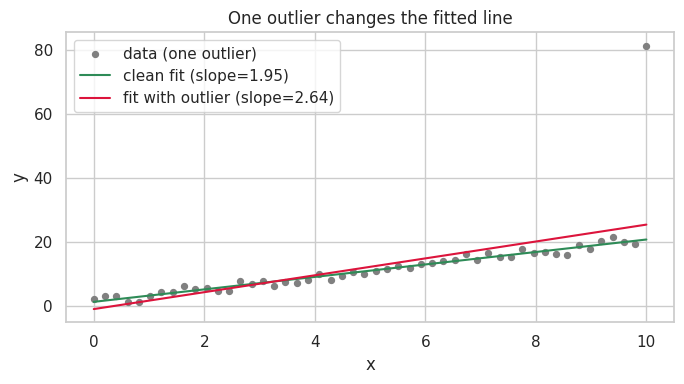

In [4]:
rng = np.random.default_rng(2024)
x = np.linspace(0, 10, 50)
y_clean = 2.0 * x + 1.0 + rng.normal(0, 1.0, size=x.size)

y_out = y_clean.copy()
y_out[-1] += 60                     # a single corrupted measurement

fit_clean = LinearRegression().fit(x.reshape(-1, 1), y_clean)
fit_out   = LinearRegression().fit(x.reshape(-1, 1), y_out)

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(x, y_out, s=18, color="gray", label="data (one outlier)")
ax.plot(x, fit_clean.predict(x.reshape(-1, 1)), color="seagreen", label=f"clean fit (slope={fit_clean.coef_[0]:.2f})")
ax.plot(x, fit_out.predict(x.reshape(-1, 1)), color="crimson", label=f"fit with outlier (slope={fit_out.coef_[0]:.2f})")
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.legend(); ax.set_title("One outlier changes the fitted line")
plt.tight_layout(); plt.show()

The true slope is 2. Contaminating a single point out of 50 visibly tilts the fitted line. Outlier handling therefore matters, although note that outliers can also be *the most interesting observations* (for example rare fraud events), so they should be investigated, not blindly deleted.

### 1.4 Detecting outliers: z-score and IQR rules

Two classical rules flag candidate outliers:

- **Z-score rule:** $|z| = \left|\dfrac{x-\mu}{\sigma}\right| > 3$
- **IQR rule (boxplot):** $x < Q_1 - 1.5\,\text{IQR}$ or $x > Q_3 + 1.5\,\text{IQR}$, with $\text{IQR}=Q_3-Q_1$

The z-score is itself distorted by outliers (they inflate $\sigma$), whereas the IQR uses *quantiles* and is more robust.

In [5]:
vals = np.append(rng.normal(50, 5, 200), [95, 110, 8])      # three planted outliers

z = (vals - vals.mean()) / vals.std()
q1, q3 = np.percentile(vals, [25, 75])
iqr = q3 - q1
iqr_mask = (vals < q1 - 1.5 * iqr) | (vals > q3 + 1.5 * iqr)

print(f"Flagged by |z| > 3 : {np.sum(np.abs(z) > 3)} points -> {np.round(vals[np.abs(z) > 3], 1)}")
print(f"Flagged by IQR rule: {iqr_mask.sum()} points -> {np.round(vals[iqr_mask], 1)}")
print(f"\nMean / std WITH outliers   : {vals.mean():.2f} / {vals.std():.2f}")
core = vals[~iqr_mask]
print(f"Mean / std WITHOUT outliers: {core.mean():.2f} / {core.std():.2f}")

Flagged by |z| > 3 : 3 points -> [ 95. 110.   8.]
Flagged by IQR rule: 4 points -> [ 35.7  95.  110.    8. ]

Mean / std WITH outliers   : 50.24 / 7.75
Mean / std WITHOUT outliers: 50.00 / 4.81


Both rules find the planted extreme values. Notice how the three outliers inflate the standard deviation relative to the clean data, which is exactly why mean/std-based scaling is fragile in the presence of outliers (we revisit this with `RobustScaler` in Section 3).

### 1.5 Preprocessing tools in scikit-learn

scikit-learn provides building blocks for all of these tasks:

- `Pipeline`: chain preprocessing and modelling so that every step is applied consistently to training and test data.
- `ColumnTransformer`: apply different preprocessing to different columns of mixed-type data.
- `sklearn.feature_selection`: keep only the most relevant features (`SelectKBest`, `RFE`, `SelectFromModel`, ...). Remember the adage: *as model complexity increases, interpretability decreases, and vice versa.*

## 2. Handling Missing Data

Missing values arise from human error, sensor failures, corrupted records, or simply because a question was not applicable. Most scikit-learn estimators cannot handle them, so we must either **drop** or **impute** (fill) them. Dropping rows is acceptable only when the dataset is large and few rows are affected; otherwise we lose information and may bias the sample.

### 2.1 Why values are missing matters

| Mechanism | Meaning | Example | Consequence |
|:----------|:--------|:--------|:------------|
| **MCAR** (Missing Completely At Random) | Missingness is unrelated to any variable | A sensor randomly drops packets | Simple imputation is usually safe |
| **MAR** (Missing At Random) | Missingness depends on *observed* variables | Older respondents skip an "app usage" question | Model-based imputation (KNN / iterative) helps |
| **MNAR** (Missing Not At Random) | Missingness depends on the *missing value itself* | High earners hide their salary | No imputer can fully fix it; consider a missing-indicator feature |

### 2.2 The book's toy dataset

We create 20 samples with 10 features drawn uniformly from $[0, 100]$ and set about 20% of the values to `NaN`, using the same seed as the book (`2024`).

In [6]:
np.random.seed(2024)                 # reproducibility (same seed as the book)
n_samples, n_features = 20, 10

data = {f"Feature{i+1}": np.random.uniform(0, 100, n_samples) for i in range(n_features)}
df = pd.DataFrame(data)

for column in df.columns:
    mask = np.random.random(n_samples) < 0.2
    df.loc[mask, column] = np.nan

total = df.size
missing = int(df.isna().sum().sum())
print(f"Shape: {df.shape} | missing cells: {missing} of {total} ({missing/total:.1%})")
print("\nMissing values per feature:")
print(df.isna().sum().to_string())
print("\nFirst 6 rows:")
df.head(6)

Shape: (20, 10) | missing cells: 44 of 200 (22.0%)

Missing values per feature:
Feature1     3
Feature2     5
Feature3     4
Feature4     4
Feature5     5
Feature6     5
Feature7     7
Feature8     6
Feature9     2
Feature10    3

First 6 rows:


,Feature1,Feature2,Feature3,Feature4,Feature5,Feature6,Feature7,Feature8,Feature9,Feature10
0,58.8015,NaN,42.0098,34.6804,49.9623,NaN,NaN,89.9546,41.1524,NaN
1,69.9109,9.5542,6.4364,31.2878,37.9665,NaN,82.0056,NaN,75.7976,91.3825
2,NaN,96.0910,59.6433,84.7104,NaN,84.1090,NaN,70.2881,1.7783,4.1177
3,NaN,25.1767,83.7324,88.0231,16.8869,97.2056,84.6968,NaN,NaN,80.0780
4,20.5019,NaN,89.2486,67.6559,58.6359,78.2257,60.9116,NaN,65.1142,99.1192
5,10.6063,76.8254,20.0527,5.3675,NaN,19.7031,34.4233,93.3995,72.2067,12.6403


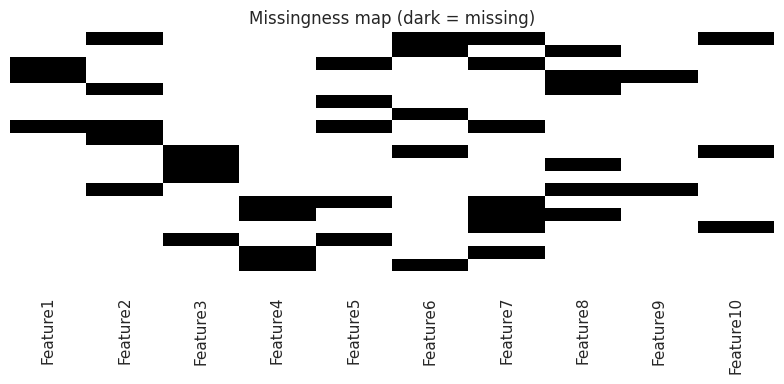

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(df.isna(), cbar=False, cmap="Greys", yticklabels=False, ax=ax)
ax.set_title("Missingness map (dark = missing)")
plt.tight_layout(); plt.show()

A missingness map is a quick way to see whether gaps are scattered randomly (as here, because we generated them that way) or concentrated in certain rows/columns, which would hint at a systematic (MAR/MNAR) cause.

### 2.3 `SimpleImputer`: replace with a statistic

`SimpleImputer` replaces every missing entry with a summary statistic of its column, learned in `fit()`:

| `strategy` | Replacement | Use for |
|:-----------|:------------|:--------|
| `"mean"` | Column mean $\mu_j$ | Symmetric numeric data |
| `"median"` | Column median | Skewed data or outliers |
| `"most_frequent"` | Mode | Categorical (or discrete) data |
| `"constant"` | A fixed `fill_value` | Domain-specific default |

In [8]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="mean")
imputed_df = pd.DataFrame(imputer.fit_transform(df), columns=df.columns)

print("Learned column means (statistics_):")
print(pd.Series(imputer.statistics_, index=df.columns).round(4).to_string())
print("\nMissing values remaining:", int(imputed_df.isna().sum().sum()))

idx = df.index[df["Feature1"].isna()].tolist()
print(f"\nFeature1 was NaN at rows {idx}; they were filled with {imputed_df.loc[idx, 'Feature1'].round(4).unique()}")
imputed_df.head(6)

Learned column means (statistics_):
Feature1    52.5586
Feature2    53.8647
Feature3    52.8975
Feature4    54.9616
Feature5    46.0559
Feature6    57.8230
Feature7    51.1450
Feature8    50.7150
Feature9    60.6167
Feature10   48.4000

Missing values remaining: 0

Feature1 was NaN at rows [2, 3, 7]; they were filled with [52.5586]


,Feature1,Feature2,Feature3,Feature4,Feature5,Feature6,Feature7,Feature8,Feature9,Feature10
0,58.8015,53.8647,42.0098,34.6804,49.9623,57.8230,51.1450,89.9546,41.1524,48.4000
1,69.9109,9.5542,6.4364,31.2878,37.9665,57.8230,82.0056,50.7150,75.7976,91.3825
2,52.5586,96.0910,59.6433,84.7104,46.0559,84.1090,51.1450,70.2881,1.7783,4.1177
3,52.5586,25.1767,83.7324,88.0231,16.8869,97.2056,84.6968,50.7150,60.6167,80.0780
4,20.5019,53.8647,89.2486,67.6559,58.6359,78.2257,60.9116,50.7150,65.1142,99.1192
5,10.6063,76.8254,20.0527,5.3675,46.0559,19.7031,34.4233,93.3995,72.2067,12.6403


Every missing entry of `Feature1` received the **same** value, the mean of the observed entries. This is fast and deterministic, but it has a known drawback: it **shrinks the variance** of the feature (many points are piled at the mean) and weakens correlations with other features.

Two useful options of `SimpleImputer`:
- `add_indicator=True` appends binary columns that mark *which* entries were missing, letting the model learn from the missingness itself (helpful for MNAR data).
- Different strategies per column are possible by combining it with `ColumnTransformer`.

In [9]:
demo = pd.DataFrame({"a": [1.0, np.nan, 3.0, 100.0], "b": [np.nan, 2.0, 2.0, 5.0]})
for strat in ["mean", "median", "most_frequent"]:
    out = SimpleImputer(strategy=strat).fit_transform(demo)
    print(f"{strat:14s} -> column a imputed value: {out[1, 0]:8.2f} | column b imputed value: {out[0, 1]:.2f}")

with_ind = SimpleImputer(strategy="median", add_indicator=True).fit_transform(demo)
print("\nWith add_indicator=True (last two columns flag the missing entries):")
print(with_ind)

mean           -> column a imputed value:    34.67 | column b imputed value: 3.00
median         -> column a imputed value:     3.00 | column b imputed value: 2.00
most_frequent  -> column a imputed value:     1.00 | column b imputed value: 2.00

With add_indicator=True (last two columns flag the missing entries):
[[  1.   2.   0.   1.]
 [  3.   2.   1.   0.]
 [  3.   2.   0.   0.]
 [100.   5.   0.   0.]]


Column `a` contains an outlier (100). The **mean** is pulled up to about 34, while the **median** stays at 3, which is the more representative value. This is why the median is preferred for skewed data.

### 2.4 `KNNImputer`: use similar samples

`KNNImputer` finds, for each sample with a gap, the $k$ **nearest samples** that have that feature observed, and fills the gap with the **mean** of their values (optionally weighted by inverse distance). The distance is a Euclidean distance that ignores coordinates that are missing (the "nan-Euclidean" distance):

$$d(\mathbf{x}_i,\mathbf{x}_j)=\sqrt{\frac{p}{p_{\text{obs}}}\sum_{l\,\in\,\text{observed in both}}(x_{il}-x_{jl})^2}$$

where $p$ is the total number of features and $p_{\text{obs}}$ the number of coordinates present in both samples.

> **Note on the book's wording.** The book describes the imputation as taking the "majority label". For *numeric* features, as here, the imputed value is the **(weighted) average** of the neighbours' values; majority voting applies to classification, not to `KNNImputer`.

In [10]:
from sklearn.impute import KNNImputer

knn_imputer = KNNImputer(n_neighbors=2)
knn_imputed_df = pd.DataFrame(knn_imputer.fit_transform(df), columns=df.columns)

idx = df.index[df["Feature1"].isna()].tolist()
cmp = pd.DataFrame({
    "SimpleImputer (mean)": imputed_df.loc[idx, "Feature1"],
    "KNNImputer (k=2)":     knn_imputed_df.loc[idx, "Feature1"],
})
print("Imputed values for the rows where Feature1 was missing:")
print(cmp.round(4))

Imputed values for the rows where Feature1 was missing:
   SimpleImputer (mean)  KNNImputer (k=2)
2               52.5586           67.7523
3               52.5586           47.8809
7               52.5586           47.6297


Unlike `SimpleImputer`, the KNN method gives **different values to different samples**, because each sample has a different set of neighbours. The price is computation: all pairwise distances are required, so the cost grows roughly with the square of the number of samples, and $k$ becomes a hyperparameter to tune.

### 2.5 `IterativeImputer`: regression-based imputation

`IterativeImputer` models each feature with missing values as a **regression** of all the other features (a round-robin procedure inspired by the MICE algorithm from statistics):

1. Initialise missing entries with a simple strategy (mean by default).
2. For each feature $j$ with gaps: treat $x_j$ as the target $y$, the other features as predictors $X$, fit a regressor on the rows where $x_j$ is observed, and predict the missing entries.
3. Repeat the cycle until the imputed values converge (or `max_iter` is reached).

It is still marked as *experimental*, so it must be enabled explicitly.

In [11]:
from sklearn.experimental import enable_iterative_imputer  # noqa: F401  (activates the experimental feature)
from sklearn.impute import IterativeImputer

iter_imputer = IterativeImputer(random_state=2024, max_iter=10)
iterative_imputed_df = pd.DataFrame(iter_imputer.fit_transform(df), columns=df.columns)

cmp = pd.DataFrame({
    "Simple (mean)": imputed_df.loc[idx, "Feature1"],
    "KNN (k=2)":     knn_imputed_df.loc[idx, "Feature1"],
    "Iterative":     iterative_imputed_df.loc[idx, "Feature1"],
})
print("Three imputers, three different answers for the same missing entries:")
print(cmp.round(4))
print("\nMissing values remaining after IterativeImputer:", int(iterative_imputed_df.isna().sum().sum()))

Three imputers, three different answers for the same missing entries:
   Simple (mean)  KNN (k=2)  Iterative
2        52.5586    67.7523    52.5397
3        52.5586    47.8809    52.6306
7        52.5586    47.6297    52.5581

Missing values remaining after IterativeImputer: 0


Three imputers give three different answers, which highlights a fundamental point: **imputation is estimation, not ground truth**. To judge which method is better we need to know the true values. We can obtain that by an *experiment*: take a complete dataset, delete values at random, impute, and compare with what we deleted.

### 2.6 Which imputer is most accurate? A controlled experiment

We run the experiment on two kinds of data:
- **Independent features** (like the book's uniform toy data): no feature carries information about the others, so there is nothing for smarter methods to exploit.
- **Correlated features** (generated from a few latent factors, like most real tables): neighbours and other columns *are* informative.

We delete 20% of the values and report the **root mean squared error (RMSE)** of the imputed values (lower is better).

In [12]:
def make_missing(X, frac, seed):
    r = np.random.default_rng(seed)
    mask = r.random(X.shape) < frac
    Xm = X.copy()
    Xm[mask] = np.nan
    return Xm, mask

def imputation_rmse(X_true, frac=0.2, seeds=(0, 1, 2, 3, 4)):
    imputers = {
        "mean":      SimpleImputer(strategy="mean"),
        "median":    SimpleImputer(strategy="median"),
        "KNN (k=5)": KNNImputer(n_neighbors=5),
        "Iterative": IterativeImputer(random_state=0, max_iter=15),
    }
    scores = {k: [] for k in imputers}
    for s in seeds:
        Xm, mask = make_missing(X_true, frac, s)
        for name, imp in imputers.items():
            X_hat = imp.fit_transform(Xm)
            scores[name].append(np.sqrt(np.mean((X_hat[mask] - X_true[mask]) ** 2)))
    return pd.Series({k: np.mean(v) for k, v in scores.items()})

rng = np.random.default_rng(10)
X_indep = rng.uniform(0, 100, size=(300, 8))                          # independent columns
latent = rng.normal(size=(300, 3))                                    # 3 hidden factors
X_corr = latent @ rng.normal(size=(3, 8)) * 10 + rng.normal(0, 3, size=(300, 8))   # correlated columns

result = pd.DataFrame({
    "independent features": imputation_rmse(X_indep),
    "correlated features":  imputation_rmse(X_corr),
})
print("Mean RMSE of the imputed values over 5 random masks (lower is better):")
result

Mean RMSE of the imputed values over 5 random masks (lower is better):


,independent features,correlated features
mean,29.3997,17.4377
median,29.5212,17.4396
KNN (k=5),32.2203,9.1925
Iterative,29.4611,4.6543


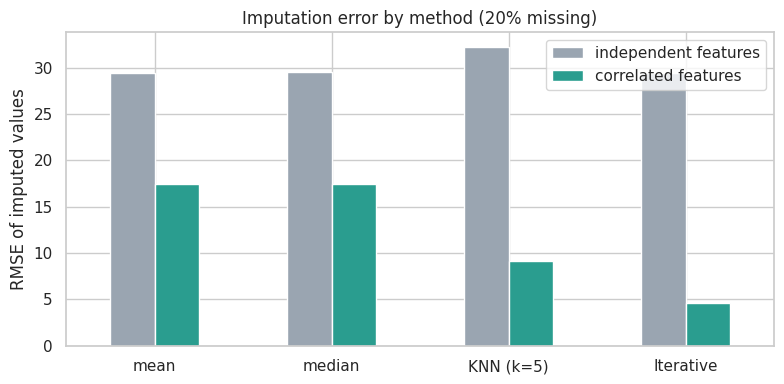

In [13]:
result.plot.bar(figsize=(8, 4), rot=0, color=["#9aa5b1", "#2a9d8f"])
plt.ylabel("RMSE of imputed values"); plt.title("Imputation error by method (20% missing)")
plt.tight_layout(); plt.show()

The experiment confirms the guidance in the book with numbers:

- On **independent** features, nothing beats a simple statistic by much. Other columns do not help, so extra sophistication buys nothing.
- On **correlated** features, `KNNImputer` and especially `IterativeImputer` produce much lower error than mean/median imputation, because they exploit the relationships between columns.

Real datasets are almost always correlated, which is why model-based imputation is worth considering when a moderate fraction of the data is missing.

**Practical guidance for choosing an imputer**

| Factor | Recommendation |
|:-------|:---------------|
| Data type | Numeric: mean/median/KNN/iterative. Categorical: `most_frequent` (or a constant such as `"missing"`) |
| Distribution | Skewed or outliers: median rather than mean |
| Fraction missing $<5\%$ | `SimpleImputer`: cheap, introduces little bias |
| Fraction missing 5-10% | `KNNImputer` (all-numeric data) or `IterativeImputer` (mixed relationships) |
| Fraction missing $>10\%$ in one column | Consider dropping that column unless it is essential; otherwise use domain-specific methods |
| Mechanism MNAR | Add missing-indicator features (`add_indicator=True`) |

### 2.7 Some models do not need imputation at all

Tree-based models can treat `NaN` as a special value. `HistGradientBoostingClassifier` (and, in recent versions, `RandomForest*` and `DecisionTree*`) accept missing values natively. We compare this with imputation on the breast-cancer dataset with 15% of values removed.

In [14]:
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression

Xb, yb = load_breast_cancer(return_X_y=True)
Xb_miss, _ = make_missing(Xb, 0.15, seed=0)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

candidates = {
    "HistGradientBoosting (native NaN)": HistGradientBoostingClassifier(random_state=0),
    "Median impute + Logistic Regression": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(max_iter=2000)),
    "KNN impute + Logistic Regression":    make_pipeline(KNNImputer(n_neighbors=5), StandardScaler(), LogisticRegression(max_iter=2000)),
    "Iterative impute + Logistic Regression": make_pipeline(IterativeImputer(random_state=0, max_iter=10), StandardScaler(), LogisticRegression(max_iter=2000)),
}
rows = []
for name, est in candidates.items():
    s = cross_val_score(est, Xb_miss, yb, cv=cv)
    rows.append({"strategy": name, "mean accuracy": s.mean(), "std": s.std()})
pd.DataFrame(rows).set_index("strategy")

,mean accuracy,std
strategy,,
HistGradientBoosting (native NaN),0.9613,0.0119
Median impute + Logistic Regression,0.9701,0.0131
KNN impute + Logistic Regression,0.9649,0.0175
Iterative impute + Logistic Regression,0.9754,0.0087


All strategies handle 15% missingness well on this easy dataset, and the differences are small relative to the fold-to-fold standard deviation. The takeaway is practical: when the algorithm supports missing values natively you may skip imputation, and when it does not, even simple imputation inside a pipeline is often adequate. Always **evaluate the choice with cross-validation**, as done here, instead of arguing about it in the abstract.

### 2.8 Hands-on workflow summary
1. Load the data and quantify missingness (per column and per row).
2. Choose an imputation method according to the table above.
3. Apply the imputer **inside a pipeline, fitted on the training data only**.
4. Compare strategies with cross-validation.

## 3. Scaling Techniques

Features often live on very different scales (age in $[0,100]$, income in $[0,100\,000]$). Scale matters for:

- **Distance-based algorithms** (KNN, K-means, SVM with RBF kernel): large-valued features dominate the distance.
- **Gradient-based and regularised models** (linear/logistic regression, neural networks, Ridge/Lasso): unscaled features give elongated loss surfaces (slow convergence) and unequal penalties.
- **PCA** (Chapter 3): directions of maximum variance are dominated by large-scale features.

Two terms that are often confused:

- **Standardisation** (z-score): centres each feature to mean 0 and scales to standard deviation 1.
- **Normalisation** (min-max): rescales each feature to a fixed range, usually $[0,1]$. (scikit-learn's `Normalizer` is a *different* operation: it rescales each **sample (row)** to unit norm.)

| Scaler | Formula | Output | Typical use |
|:-------|:--------|:-------|:------------|
| `StandardScaler` | $z=\dfrac{x-\mu}{\sigma}$ | Mean 0, std 1, unbounded | Roughly Gaussian features; linear models, SVM, PCA |
| `MinMaxScaler` | $x'=\dfrac{x-x_{\min}}{x_{\max}-x_{\min}}$ | Bounded in $[0,1]$ | Bounded inputs, neural networks, image pixels |
| `Normalizer` | $\mathbf{x}'=\dfrac{\mathbf{x}}{\lVert\mathbf{x}\rVert}$ (per row) | Each row has unit L1 or L2 norm | Text/sparse data, cosine-similarity tasks |
| `RobustScaler` | $x'=\dfrac{x-\text{median}}{Q_3-Q_1}$ | Median 0, IQR 1 | Data with outliers |

We reuse the iteratively-imputed DataFrame from Section 2 (as the book does).

### 3.1 `StandardScaler`

In [15]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, Normalizer, RobustScaler

scaler = StandardScaler()
scaled_df = pd.DataFrame(scaler.fit_transform(iterative_imputed_df), columns=iterative_imputed_df.columns)

print("Learned mu (mean_)   :", np.round(scaler.mean_[:4], 2), "...")
print("Learned sigma (scale_):", np.round(scaler.scale_[:4], 2), "...")
print("\nColumn means after scaling :", np.round(scaled_df.mean().values[:4], 10), "...")
print("Column stds after scaling  :", np.round(scaled_df.std(ddof=0).values[:4], 4), "...")
scaled_df.head(6)

Learned mu (mean_)   : [52.56 53.9  52.9  54.96] ...
Learned sigma (scale_): [22.95 23.65 29.18 22.68] ...

Column means after scaling : [-0.  0.  0. -0.] ...
Column stds after scaling  : [1. 1. 1. 1.] ...


,Feature1,Feature2,Feature3,Feature4,Feature5,Feature6,Feature7,Feature8,Feature9,Feature10
0,0.2719,0.0195,-0.3731,-0.8943,0.1888,0.0318,0.0019,1.6838,-0.7809,-0.0036
1,0.7560,-1.8749,-1.5922,-1.0439,-0.3917,0.0859,1.4269,-0.0005,0.6525,1.4291
2,-0.0009,1.7835,0.2313,1.3120,0.0029,1.0216,0.0009,0.8397,-2.4099,-1.4723
3,0.0030,-1.2145,1.0568,1.4580,-1.4118,1.5313,1.5513,-0.0018,-0.3879,1.0532
4,-1.3971,-0.0298,1.2459,0.5599,0.6085,0.7926,0.4518,-0.0013,0.2105,1.6863
5,-1.8283,0.9690,-1.1255,-2.1869,0.0046,-1.4853,-0.7726,1.8317,0.5039,-1.1889


After standardisation every column has mean 0 and standard deviation 1. Values are z-scores: $+1.5$ means "1.5 standard deviations above the column mean". Because of centring, some values become **negative**, and the range is not bounded.

### 3.2 `MinMaxScaler`

In [16]:
minmax = MinMaxScaler()
minmax_df = pd.DataFrame(minmax.fit_transform(iterative_imputed_df), columns=iterative_imputed_df.columns)

print("Per-column minimum after scaling:", minmax_df.min().round(4).unique())
print("Per-column maximum after scaling:", minmax_df.max().round(4).unique())
minmax_df.head(6)

Per-column minimum after scaling: [0.]
Per-column maximum after scaling: [1.]


,Feature1,Feature2,Feature3,Feature4,Feature5,Feature6,Feature7,Feature8,Feature9,Feature10
0,0.6035,0.5178,0.3805,0.3546,0.5690,0.5559,0.4350,0.9628,0.4022,0.4650
1,0.7214,0.0000,0.0004,0.3136,0.4131,0.5719,0.8331,0.5386,0.7560,0.9186
2,0.5371,1.0000,0.5690,0.9599,0.5191,0.8490,0.4347,0.7502,0.0000,0.0000
3,0.5380,0.1805,0.8264,1.0000,0.1390,1.0000,0.8678,0.5383,0.4992,0.7996
4,0.1972,0.5043,0.8854,0.7536,0.6818,0.7812,0.5607,0.5384,0.6469,1.0000
5,0.0922,0.7774,0.1459,0.0000,0.5195,0.1066,0.2187,1.0000,0.7193,0.0897


Every column now spans exactly $[0, 1]$. `MinMaxScaler` preserves the *shape* of the original distribution, but it is sensitive to outliers: one extreme value defines $x_{\max}$ and squeezes all the other values into a narrow band.

### 3.3 `Normalizer` (per-sample scaling)

`Normalizer` operates on **rows**. With `norm="l2"` each sample vector is divided by its Euclidean length, and with `norm="l1"` by the sum of absolute values:

$$\lVert\mathbf{x}\rVert_1=\sum_{j=1}^{p}|x_j|, \qquad \lVert\mathbf{x}\rVert_2=\sqrt{\sum_{j=1}^{p}x_j^2}$$

In [17]:
for norm in ["l1", "l2"]:
    nz = Normalizer(norm=norm)
    out = nz.fit_transform(iterative_imputed_df)
    row_norms = np.linalg.norm(out, ord=1 if norm == "l1" else 2, axis=1)
    print(f"Normalizer({norm!r}): norm of every row = {np.round(row_norms[:5], 6)} ... "
          f"(all equal to 1: {np.allclose(row_norms, 1)})")

normalized_df = pd.DataFrame(Normalizer().fit_transform(iterative_imputed_df), columns=iterative_imputed_df.columns)
normalized_df.head(6)

Normalizer('l1'): norm of every row = [1. 1. 1. 1. 1.] ... (all equal to 1: True)
Normalizer('l2'): norm of every row = [1. 1. 1. 1. 1.] ... (all equal to 1: True)


,Feature1,Feature2,Feature3,Feature4,Feature5,Feature6,Feature7,Feature8,Feature9,Feature10
0,0.3392,0.3136,0.2423,0.2000,0.2882,0.3385,0.2952,0.5189,0.2374,0.2786
1,0.3767,0.0515,0.0347,0.1686,0.2046,0.3237,0.4419,0.2732,0.4084,0.4924
2,0.2643,0.4834,0.3001,0.4262,0.2320,0.4232,0.2574,0.3536,0.0089,0.0207
3,0.2438,0.1166,0.3878,0.4077,0.0782,0.4502,0.3923,0.2347,0.2346,0.3709
4,0.0959,0.2489,0.4175,0.3165,0.2743,0.3659,0.2849,0.2371,0.3046,0.4637
5,0.0681,0.4934,0.1288,0.0345,0.2964,0.1265,0.2211,0.5998,0.4637,0.0812


Every **row** now has unit length. This is useful when the *direction* of the vector matters more than its magnitude (text frequency vectors, cosine similarity) but is usually not what you want for ordinary tabular features. Note that `Normalizer.fit()` learns nothing (it is stateless): each row is processed independently.

### 3.4 Visual comparison on one feature

The three approaches transform the same column in very different ways. Because standardisation and min-max scaling are *linear*, the **shape** of the histogram is preserved; only axis labels change.

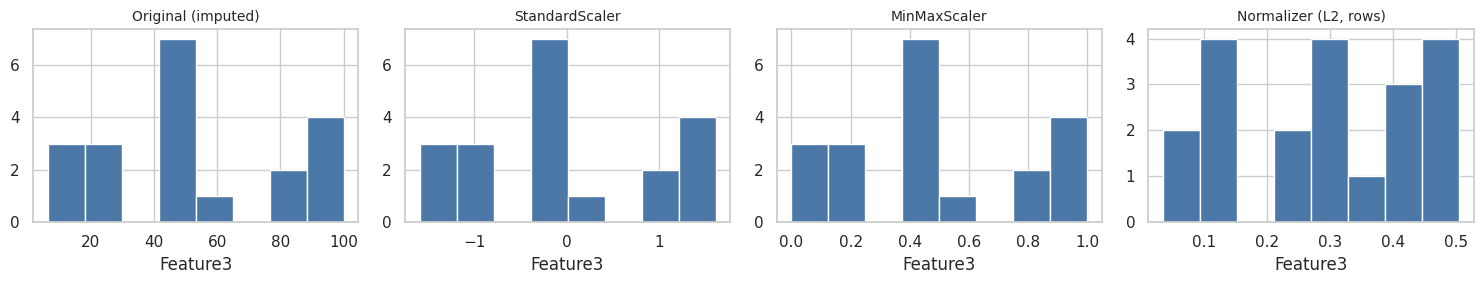

In [18]:
col = "Feature3"
fig, axes = plt.subplots(1, 4, figsize=(15, 3))
panels = [("Original (imputed)", iterative_imputed_df[col]), ("StandardScaler", scaled_df[col]),
          ("MinMaxScaler", minmax_df[col]), ("Normalizer (L2, rows)", normalized_df[col])]
for ax, (title, series) in zip(axes, panels):
    ax.hist(series, bins=8, color="#4c78a8", edgecolor="white")
    ax.set_title(title, fontsize=10)
    ax.set_xlabel(col)
plt.tight_layout(); plt.show()

### 3.5 When outliers are present: `RobustScaler`

`RobustScaler` centres on the **median** and scales by the **IQR**, so a few extreme values barely affect the result. We compare it with the standard scaler on data containing one huge outlier.

In [19]:
r = np.random.default_rng(5)
feature = np.append(r.normal(100, 10, 99), 1000).reshape(-1, 1)      # one extreme value

std_out = StandardScaler().fit_transform(feature).ravel()
rob_out = RobustScaler().fit_transform(feature).ravel()

print("Spread of the 99 'normal' points after scaling (std of the bulk):")
print(f"  StandardScaler: {std_out[:-1].std():.3f}   <- squashed, because sigma was inflated by the outlier")
print(f"  RobustScaler  : {rob_out[:-1].std():.3f}   <- still has a sensible spread")
print(f"\nThe outlier itself maps to z = {std_out[-1]:.1f} (standard) vs {rob_out[-1]:.1f} (robust)")

Spread of the 99 'normal' points after scaling (std of the bulk):
  StandardScaler: 0.098   <- squashed, because sigma was inflated by the outlier
  RobustScaler  : 0.640   <- still has a sensible spread

The outlier itself maps to z = 9.9 (standard) vs 65.1 (robust)


With standard scaling the outlier inflates $\sigma$, so the bulk of the data is compressed into a narrow range. `RobustScaler` keeps the bulk well spread and leaves the outlier visibly far away, which is the behaviour we want before fitting a scale-sensitive model.

### 3.6 Which models actually care about scaling?

We evaluate five different algorithms on the Wine data with three preprocessing choices (none, standardisation, min-max), using 5-fold cross-validation. The scaler is inside a pipeline, so there is no leakage.

In [20]:
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

models = {
    "KNN":                 KNeighborsClassifier(),
    "SVM (RBF)":           SVC(),
    "Logistic Regression": LogisticRegression(max_iter=5000),
    "Decision Tree":       DecisionTreeClassifier(random_state=0),
    "Random Forest":       RandomForestClassifier(n_estimators=200, random_state=0),
}
scalers = {"none": "passthrough", "StandardScaler": StandardScaler(), "MinMaxScaler": MinMaxScaler()}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=2024)
table = {}
for m_name, model in models.items():
    table[m_name] = {}
    for s_name, sc in scalers.items():
        pipe = Pipeline([("scale", sc), ("model", model)])
        table[m_name][s_name] = cross_val_score(pipe, Xw, yw, cv=cv).mean()

scaling_table = pd.DataFrame(table).T
scaling_table.style.background_gradient(cmap="Blues", axis=None).format("{:.4f}")

,none,StandardScaler,MinMaxScaler
KNN,0.7019,0.9551,0.9552
SVM (RBF),0.6968,0.9886,0.9887
Logistic Regression,0.9606,0.9830,0.9832
Decision Tree,0.9325,0.9325,0.9325
Random Forest,0.9776,0.9776,0.9776


The pattern is exactly what theory predicts:

- **KNN** and **SVM** improve dramatically with scaling (they depend on distances).
- **Logistic regression** also benefits, although less dramatically (faster, more stable optimisation and equal regularisation across features).
- **Decision trees and random forests** are essentially **unaffected**, because a split on `proline > 755` is equivalent to a split on its standardised version. Scaling trees is harmless but unnecessary.

So the book's advice that tree-based methods "do not need scaling" is correct, and the rule of thumb is: *scale for distance-based and gradient-based models; skip it for trees.*

## 4. Encoding Categorical Variables

Most ML algorithms require numeric input. Categorical variables come in two flavours:

- **Nominal**: no inherent order (colour, department, city).
- **Ordinal**: a meaningful order (education level, `Junior < Senior < Manager`, ratings 1-5).

The encoding must reflect this nature. Using the wrong one injects a fake order, or throws away a real one.

| Encoder | Output | Best for | Watch out for |
|:--------|:-------|:---------|:--------------|
| `OneHotEncoder` | One binary column per category | Nominal features, low/medium cardinality | Many categories → many sparse columns |
| `OrdinalEncoder` | One integer column (order you specify) | Ordinal features, tree models | Implies equal spacing between levels |
| `LabelEncoder` | Integer codes | **Target variable `y` only** | Do not use on input features |
| `TargetEncoder` | Mean of the target per category | High-cardinality nominal features | Leakage if not cross-fitted (sklearn does this for you) |

### 4.1 The book's toy dataset

In [21]:
np.random.seed(2024)
categorical_data = pd.DataFrame({
    "Department": np.random.choice(["A", "B", "C", "D"], size=20),
    "Position":   np.random.choice(["Junior", "Senior", "Manager"], size=20),
    "Location":   np.random.choice(["NY", "SF", "LA", "CHI"], size=20),
})
print("Cardinality per column:", categorical_data.nunique().to_dict())
categorical_data.head(8)

Cardinality per column: {'Department': 4, 'Position': 3, 'Location': 4}


,Department,Position,Location
0,A,Manager,LA
1,C,Manager,LA
2,A,Junior,NY
3,A,Manager,LA
4,D,Manager,NY
5,A,Senior,LA
6,C,Manager,SF
7,D,Manager,LA


### 4.2 `OneHotEncoder`

One-hot encoding creates a binary column for every category: a `1` marks the category that applies to a row. With `Department` having categories A-D, we get four new columns `Department_A ... Department_D`.

In [22]:
from sklearn.preprocessing import OneHotEncoder

onehot = OneHotEncoder(sparse_output=False)
onehot_df = pd.DataFrame(onehot.fit_transform(categorical_data), columns=onehot.get_feature_names_out())

print(f"Shape: {categorical_data.shape} -> {onehot_df.shape}  (3 columns became {onehot_df.shape[1]})")
print("Row sums are 3 (exactly one '1' per original feature):", set(onehot_df.sum(axis=1).astype(int)))
onehot_df.head(6)

Shape: (20, 3) -> (20, 11)  (3 columns became 11)
Row sums are 3 (exactly one '1' per original feature): {3}


,Department_A,Department_B,Department_C,Department_D,Position_Junior,Position_Manager,Position_Senior,Location_CHI,Location_LA,Location_NY,Location_SF
0,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000
1,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000
2,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000
3,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000
4,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,1.0000,0.0000
5,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000


The three original columns expanded into $4+3+4=11$ binary columns. Useful options:

- `drop="first"`: drops one category per feature to avoid the **dummy-variable trap** (perfect multicollinearity: the dropped column is implied by the others). This matters for un-regularised linear models.
- `handle_unknown="ignore"`: encodes categories unseen during training as all zeros instead of raising an error. Essential in production.
- `min_frequency` / `max_categories`: group rare categories together.
- `sparse_output=True` (default): returns a memory-efficient sparse matrix.

In [23]:
enc_drop = OneHotEncoder(drop="first", sparse_output=False).fit(categorical_data)
print("drop='first' columns:", list(enc_drop.get_feature_names_out()))

enc_safe = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(categorical_data[["Department"]])
unseen = pd.DataFrame({"Department": ["Z"]})                     # category never seen in fit
print("\nUnseen category 'Z' with handle_unknown='ignore' ->", enc_safe.transform(unseen))

try:
    OneHotEncoder(sparse_output=False).fit(categorical_data[["Department"]]).transform(unseen)
except ValueError as e:
    print("Default settings raise:", str(e)[:70], "...")

drop='first' columns: ['Department_B', 'Department_C', 'Department_D', 'Position_Manager', 'Position_Senior', 'Location_LA', 'Location_NY', 'Location_SF']

Unseen category 'Z' with handle_unknown='ignore' -> [[0. 0. 0. 0.]]
Default settings raise: Found unknown categories ['Z'] in column 0 during transform ...


### 4.3 `OrdinalEncoder` and the danger of arbitrary integers

For an ordinal feature we can specify the order explicitly, so the numbers carry meaning (`Junior=0 < Senior=1 < Manager=2`).

In [24]:
from sklearn.preprocessing import OrdinalEncoder

ord_enc = OrdinalEncoder(categories=[["Junior", "Senior", "Manager"]])
position_encoded = ord_enc.fit_transform(categorical_data[["Position"]])
pd.DataFrame({"Position": categorical_data["Position"], "encoded": position_encoded.ravel()}).drop_duplicates().sort_values("encoded")

,Position,encoded
2,Junior,0.0000
5,Senior,1.0000
0,Manager,2.0000


Why does the choice between integer codes and one-hot matter? An integer code tells a **linear model** that the categories are equally spaced along a line. If the true effect of a nominal variable is *not monotonic*, a single integer column cannot represent it. The following simulation makes this concrete: the target depends on a nominal `city` feature in a non-monotonic way.

In [25]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

r = np.random.default_rng(0)
cities = np.array(["Bandung", "Jakarta", "Surabaya", "Medan"])
effect = {"Bandung": 10.0, "Jakarta": 40.0, "Surabaya": 5.0, "Medan": 30.0}     # no monotonic pattern

city = r.choice(cities, size=1000)
y_city = np.array([effect[c] for c in city]) + r.normal(0, 2, 1000)
X_city = pd.DataFrame({"city": city})
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(X_city, y_city, test_size=0.3, random_state=0)

as_integer = make_pipeline(OrdinalEncoder(), LinearRegression()).fit(Xc_tr, yc_tr)
as_onehot  = make_pipeline(OneHotEncoder(handle_unknown="ignore"), LinearRegression()).fit(Xc_tr, yc_tr)

print(f"Linear model with arbitrary integer codes: test R^2 = {r2_score(yc_te, as_integer.predict(Xc_te)):.3f}")
print(f"Linear model with one-hot encoding       : test R^2 = {r2_score(yc_te, as_onehot.predict(Xc_te)):.3f}")

Linear model with arbitrary integer codes: test R^2 = 0.055
Linear model with one-hot encoding       : test R^2 = 0.982


The integer encoding fails badly because it forces a straight-line relationship across an arbitrary ordering, while one-hot encoding lets each city have its own effect and recovers nearly all of the signal. (Tree-based models can split an integer code repeatedly, so they are much less affected, which is why ordinal codes are common in tree pipelines.)

### 4.4 `LabelEncoder`: for targets only

The book applies `LabelEncoder` column by column to the features. It works mechanically, but scikit-learn's documentation states that `LabelEncoder` is designed for the **target variable** `y`; for input features use `OrdinalEncoder` (or one-hot). Applied to features, it assigns arbitrary alphabetical integers that models may misread as meaningful distances (the same problem demonstrated above).

In [26]:
from sklearn.preprocessing import LabelEncoder

# Reproducing the book's application (works, but not recommended for features)
label_encoded_df = pd.DataFrame()
for column in categorical_data.columns:
    label_encoded_df[f"{column}_encoded"] = LabelEncoder().fit_transform(categorical_data[column])
print("Book-style label encoding of the features:")
print(label_encoded_df.head(6).to_string())

# Intended use: encode a class-label vector
y_text = np.array(["spam", "ham", "ham", "spam", "ham"])
le = LabelEncoder().fit(y_text)
print("\nIntended use on a target vector:", y_text, "->", le.transform(y_text), "| classes_:", le.classes_)
print("Decoded back:", le.inverse_transform([1, 0, 0]))

Book-style label encoding of the features:
   Department_encoded  Position_encoded  Location_encoded
0                   0                 1                 1
1                   2                 1                 1
2                   0                 0                 2
3                   0                 1                 1
4                   3                 1                 2
5                   0                 2                 1

Intended use on a target vector: ['spam' 'ham' 'ham' 'spam' 'ham'] -> [1 0 0 1 0] | classes_: ['ham' 'spam']
Decoded back: ['spam' 'ham' 'ham']


### 4.5 `TargetEncoder`: handling high-cardinality categories

When a feature has hundreds of categories (zip code, product ID), one-hot encoding creates hundreds of columns. `TargetEncoder` (available since scikit-learn 1.3) replaces each category by a **smoothed mean of the target** for that category. To avoid leakage, `fit_transform` uses internal cross-fitting: each row is encoded with statistics computed from *other* folds.

In [27]:
from sklearn.preprocessing import TargetEncoder

r = np.random.default_rng(1)
n, n_cat = 3000, 200
zip_code = r.integers(0, n_cat, size=n).astype(str)
true_effect = {z: r.normal(0, 5) for z in np.unique(zip_code)}
y_zip = np.array([true_effect[z] for z in zip_code]) + r.normal(0, 3, size=n)
X_zip = pd.DataFrame({"zip": zip_code})
Xz_tr, Xz_te, yz_tr, yz_te = train_test_split(X_zip, y_zip, test_size=0.3, random_state=0)

ohe_model = make_pipeline(OneHotEncoder(handle_unknown="ignore"), LinearRegression()).fit(Xz_tr, yz_tr)
te_model  = make_pipeline(TargetEncoder(random_state=0), LinearRegression()).fit(Xz_tr, yz_tr)

n_ohe_cols = ohe_model[0].transform(Xz_te).shape[1]
print(f"One-hot: {n_ohe_cols} columns   -> test R^2 = {r2_score(yz_te, ohe_model.predict(Xz_te)):.3f}")
print(f"Target encoding: 1 column    -> test R^2 = {r2_score(yz_te, te_model.predict(Xz_te)):.3f}")

One-hot: 200 columns   -> test R^2 = 0.716
Target encoding: 1 column    -> test R^2 = 0.715


Target encoding compresses 200 categories into **one** numeric column, while keeping most of the predictive information. The trade-offs are that it needs a target (so it must always be inside a pipeline and fitted on training data only), and it is less interpretable than one-hot columns.

### 4.6 `ColumnTransformer`: different treatment for different columns

Real tables mix numeric and categorical columns. `ColumnTransformer` applies transformers to chosen columns and concatenates the results. We reproduce the book's mixed dataset (seed 2024).

In [28]:
from sklearn.compose import ColumnTransformer

np.random.seed(2024)
mixed_data = pd.DataFrame({
    "Age":        np.random.randint(25, 65, size=20),
    "Salary":     np.round(np.random.normal(60000, 15000, size=20), 2),
    "Experience": np.random.randint(1, 20, size=20),
    "Department": np.random.choice(["IT", "HR", "Sales", "Finance"], size=20),
    "Position":   np.random.choice(["Junior", "Senior", "Manager"], size=20),
})

column_transformer = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), ["Age", "Salary", "Experience"]),
        ("cat", OneHotEncoder(), ["Department", "Position"]),
    ],
    remainder="passthrough",       # columns not listed are kept as they are
)
transformed = column_transformer.fit_transform(mixed_data)
feature_names = column_transformer.get_feature_names_out()

print("Output shape:", transformed.shape)
print("Output columns:", list(feature_names))
transformed_df = pd.DataFrame(transformed.toarray() if hasattr(transformed, "toarray") else transformed, columns=feature_names)
transformed_df.head(6)

Output shape: (20, 10)
Output columns: ['num__Age', 'num__Salary', 'num__Experience', 'cat__Department_Finance', 'cat__Department_HR', 'cat__Department_IT', 'cat__Department_Sales', 'cat__Position_Junior', 'cat__Position_Manager', 'cat__Position_Senior']


,num__Age,num__Salary,num__Experience,cat__Department_Finance,cat__Department_HR,cat__Department_IT,cat__Department_Sales,cat__Position_Junior,cat__Position_Manager,cat__Position_Senior
0,-1.0453,-0.3050,0.3273,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000
1,0.7277,1.1051,1.2625,0.0000,0.0000,0.0000,1.0000,1.0000,0.0000,0.0000
2,-1.6364,-1.5818,1.0754,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000
3,0.3583,-1.5772,-0.6078,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000
4,1.0232,-0.5652,-0.4208,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000
5,-1.5625,0.8524,-0.2338,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000


Numeric columns were standardised and categorical columns one-hot encoded in a single step. `get_feature_names_out()` gives meaningful names with a prefix (`num__`, `cat__`) identifying the transformer that produced each column. This is far more convenient than the manual name-building required in older versions.

Instead of listing columns by hand, `make_column_selector` picks them by data type:

In [29]:
from sklearn.compose import make_column_selector

auto_ct = ColumnTransformer([
    ("num", StandardScaler(), make_column_selector(dtype_include=np.number)),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), make_column_selector(dtype_exclude=np.number)),
])
auto_ct.fit(mixed_data)
print("Automatically routed columns:")
for name, _, cols in auto_ct.transformers_:
    print(f"  {name}: {list(cols)}")

Automatically routed columns:
  num: ['Age', 'Salary', 'Experience']
  cat: ['Department', 'Position']


### 4.7 Cardinality warning: one-hot can explode

A final reminder of the cost: the number of one-hot columns equals the number of distinct categories, and a dataset with several high-cardinality features can end up much *wider* than it is tall.

In [30]:
r = np.random.default_rng(3)
big = pd.DataFrame({
    "user_id": r.integers(0, 5000, size=10000).astype(str),
    "product": r.integers(0, 800, size=10000).astype(str),
    "country": r.choice(["ID", "MY", "SG", "TH", "VN"], size=10000),
})
sparse_out = OneHotEncoder().fit_transform(big)
dense_mb = sparse_out.shape[0] * sparse_out.shape[1] * 8 / 1e6
sparse_mb = (sparse_out.data.nbytes + sparse_out.indices.nbytes + sparse_out.indptr.nbytes) / 1e6

print("Original shape:", big.shape, "-> one-hot shape:", sparse_out.shape)
print(f"Memory if stored densely: {dense_mb:,.0f} MB   vs   sparse storage: {sparse_mb:.2f} MB")

Original shape: (10000, 3) -> one-hot shape: (10000, 5130)
Memory if stored densely: 410 MB   vs   sparse storage: 0.40 MB


The sparse representation (the default of `OneHotEncoder`) keeps memory small, but some algorithms still struggle with thousands of columns. For such features, consider `TargetEncoder`, `min_frequency` to group rare levels, or hashing (`FeatureHasher`).

## 5. Introduction to Pipelines

A `Pipeline` is a sequence of named steps executed in order. All steps except the last are transformers; the last may be an estimator. In this chapter's context pipelines have a crucial role: they **make correct preprocessing the default**.

Advantages:

| Advantage | Explanation |
|:----------|:------------|
| Sequential execution | Steps always run in the defined order, for both training and test data |
| Code simplification | A whole workflow is one object |
| Consistency / no leakage | Each step is fitted only on training data, even inside cross-validation |
| Easy tuning | `GridSearchCV` can tune preprocessing and model parameters together (`step__param`) |
| Modularity | Swap a step without rewriting the rest |

General syntax:

```python
pipeline = Pipeline([("name of step", transformer), ..., ("name of final step", estimator)])
```

### 5.1 Splitting *before* transforming

> **Always split the data first, then fit transformations on the training portion only.**

- **Avoids leakage:** statistics (means, medians, selected features) computed on all the data include information from the test rows, which inflates performance estimates.
- **Realistic evaluation:** in production the model sees new data it has never been fitted on.
- **Consistency:** the same parameters learned on the training data are applied to the test data.

We illustrate the mechanics with the book's pipeline (imputer → scaler), using the toy DataFrame from Section 2.

In [31]:
from sklearn.pipeline import Pipeline

# Treat the last column of the toy data as a numeric "target" purely for illustration
X = df.iloc[:, :-1]
y = df.iloc[:, -1].fillna(df.iloc[:, -1].mean())

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2024)

pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),      # handle missing values
    ("scaler",  StandardScaler()),                    # scale the features
])

X_train_transformed = pipeline.fit_transform(X_train)   # learn + apply on training data
X_test_transformed  = pipeline.transform(X_test)        # apply the SAME learned parameters

print("Train shape:", X_train_transformed.shape, "| Test shape:", X_test_transformed.shape)
print("Train column means (≈0 by construction):", np.round(X_train_transformed.mean(axis=0)[:4], 6))
print("Test column means  (NOT 0: uses train statistics):", np.round(X_test_transformed.mean(axis=0)[:4], 3))

Train shape: (16, 9) | Test shape: (4, 9)
Train column means (≈0 by construction): [-0. -0.  0.  0.]
Test column means  (NOT 0: uses train statistics): [ 1.009 -0.15  -0.023  0.907]


The training data are exactly standardised, while the test data are *not*: they were transformed with the training mean and standard deviation, just as they would be in production. That is the correct and honest behaviour.

### 5.2 Keeping column names with `set_output`

By default transformers return NumPy arrays and lose column names. Since version 1.2, `set_output(transform="pandas")` makes them return DataFrames (the book rebuilds the DataFrame manually; this does it automatically).

In [32]:
pipeline_pd = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler",  StandardScaler()),
]).set_output(transform="pandas")

X_train_df = pipeline_pd.fit_transform(X_train)
print(type(X_train_df).__name__, "with index and columns preserved:")
X_train_df.head(4)

DataFrame with index and columns preserved:


,Feature1,Feature2,Feature3,Feature4,Feature5,Feature6,Feature7,Feature8,Feature9
13,2.1076,-0.4778,1.3973,0.0000,0.0000,-1.8292,0.0000,0.0356,1.2335
12,0.5670,-0.0000,-0.0095,-0.8827,1.9383,1.4042,-1.6127,0.0000,0.0000
16,-0.0903,1.0267,0.0000,-1.1958,0.0000,-0.9534,1.9149,-0.7597,0.4410
5,-1.5613,0.9562,-1.1741,-1.9216,0.0000,-1.4713,-1.0007,1.9779,0.5691


### 5.3 Visualising a pipeline

`set_config(display="diagram")` renders pipelines as interactive diagrams in Jupyter (click a box to see its parameters).

In [33]:
from sklearn import set_config
set_config(display="diagram")
pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('imputer', ...), ('scaler', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'mean'
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a fea

### 5.4 Pipelines tune preprocessing and model together

Because a pipeline is itself an estimator, `GridSearchCV` can choose the imputation strategy, the scaler and the model hyperparameters in one search. Parameter names use the `step__parameter` convention. Here we do it on the breast-cancer data with 10% of values removed.

In [34]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC

Xbm, _ = make_missing(Xb, 0.10, seed=1)
Xbm_tr, Xbm_te, yb_tr, yb_te = train_test_split(Xbm, yb, test_size=0.25, random_state=0, stratify=yb)

search_pipe = Pipeline([
    ("imputer", SimpleImputer()),
    ("scaler",  StandardScaler()),
    ("clf",     SVC()),
])
grid = {
    "imputer__strategy": ["mean", "median"],
    "scaler": [StandardScaler(), MinMaxScaler(), RobustScaler()],
    "clf__C": [0.1, 1, 10],
}
gs = GridSearchCV(search_pipe, grid, cv=5, n_jobs=-1).fit(Xbm_tr, yb_tr)

print("Best combination:", {k: (type(v).__name__ if hasattr(v, "fit") else v) for k, v in gs.best_params_.items()})
print(f"Best cross-validated accuracy: {gs.best_score_:.4f}")
print(f"Held-out test accuracy       : {gs.score(Xbm_te, yb_te):.4f}")

Best combination: {'clf__C': 1, 'imputer__strategy': 'median', 'scaler': 'StandardScaler'}
Best cross-validated accuracy: 0.9813
Held-out test accuracy       : 0.9441


The search explored $2\times3\times3=18$ combinations of imputer strategy, scaler type and SVM penalty, each evaluated with 5-fold CV where *every step was refitted on the training folds only*. Treating preprocessing choices as hyperparameters is one of the most powerful habits you can adopt.

### 5.5 Hands-on workflow
1. Decide which preprocessing steps the data need (imputation, scaling, encoding).
2. Pick an estimator for the task.
3. Chain everything with `Pipeline`.
4. `fit` on the training data and `predict`/`score` on new data.
5. Evaluate with appropriate metrics (and cross-validation).

## 6. Feature Engineering

Feature engineering is an umbrella term for two activities:

1. **Feature extraction / creation:** transform existing data into new variables that expose patterns (e.g. `total_spending = price × quantity`).
2. **Feature selection:** keep the informative features and drop the noisy or redundant ones.

Good features can make a simple model generalise better than a complex model on raw features. Selection methods fall into three families:

| Family | How it works | Examples |
|:-------|:-------------|:---------|
| **Filter** | Scores each feature by a statistical property, independent of any model | `VarianceThreshold`, `SelectKBest` |
| **Wrapper** | Trains models on feature subsets and keeps the best subset | `RFE`, `RFECV` |
| **Embedded** | Selection happens during model training | `SelectFromModel` with Lasso / tree importances |

For the demonstrations we use the **Diabetes** dataset (442 patients, 10 numeric features, target = disease progression), which ships with scikit-learn. Its features are already mean-centred and scaled.

In [35]:
from sklearn.datasets import load_diabetes

diab = load_diabetes(as_frame=True)
Xd, yd = diab.data, diab.target
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(Xd, yd, test_size=0.2, random_state=2024)
print("Features:", list(Xd.columns))
Xd_tr.head()

Features: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
424,0.0018,0.0507,0.0110,-0.0194,-0.0167,-0.0038,-0.0471,0.0343,0.0241,0.0238
121,0.0635,-0.0446,0.0175,0.0219,0.0081,0.0215,-0.0360,0.0343,0.0199,0.0113
15,-0.0527,0.0507,-0.0181,0.0804,0.0892,0.1077,-0.0397,0.1081,0.0361,-0.0425
5,-0.0927,-0.0446,-0.0407,-0.0194,-0.0690,-0.0793,0.0413,-0.0764,-0.0412,-0.0963
21,-0.0854,0.0507,-0.0224,0.0012,-0.0373,-0.0264,0.0155,-0.0395,-0.0721,-0.0176


### 6.1 Mathematical transformations: `PolynomialFeatures`

`PolynomialFeatures(degree=2)` generates all polynomial and **interaction** terms. For features $x_1, x_2$ it creates $1,\; x_1,\; x_2,\; x_1^2,\; x_1x_2,\; x_2^2$. The number of output columns for $p$ features and degree $d$ is $\binom{p+d}{d}$, which grows quickly.

In [36]:
from sklearn.preprocessing import PolynomialFeatures
from math import comb

poly = PolynomialFeatures(degree=2, include_bias=False)
poly_arr = poly.fit_transform(Xd_tr)
poly_df = pd.DataFrame(poly_arr, columns=poly.get_feature_names_out(Xd_tr.columns))

print(f"Original features: {Xd_tr.shape[1]} -> polynomial (degree 2): {poly_df.shape[1]}")
print("Formula check: C(p+d, d) - 1 =", comb(10 + 2, 2) - 1)
print("Some generated names:", list(poly_df.columns[8:16]))

for d in [1, 2, 3, 4]:
    print(f"  degree {d}: {PolynomialFeatures(degree=d, include_bias=False).fit_transform(Xd_tr).shape[1]} features")

Original features: 10 -> polynomial (degree 2): 65
Formula check: C(p+d, d) - 1 = 65
Some generated names: ['s5', 's6', 'age^2', 'age sex', 'age bmi', 'age bp', 'age s1', 'age s2']
  degree 1: 10 features
  degree 2: 65 features
  degree 3: 285 features
  degree 4: 1000 features


Ten features became 65 columns (10 originals, 10 squares, and 45 pairwise interactions). Degree 4 already yields hundreds of columns, so polynomial expansion must be combined with regularisation or feature selection. `interaction_only=True` keeps only products of *different* features.

### 6.2 `KBinsDiscretizer`: continuous to categorical

`KBinsDiscretizer` partitions a continuous variable into `n_bins` buckets. The `strategy` decides the bucket edges:

- `uniform`: equal-width bins (1-3, 4-6, ...)
- `quantile`: equal-count bins (each bin holds the same number of samples)
- `kmeans`: bins defined by 1-D K-means clustering

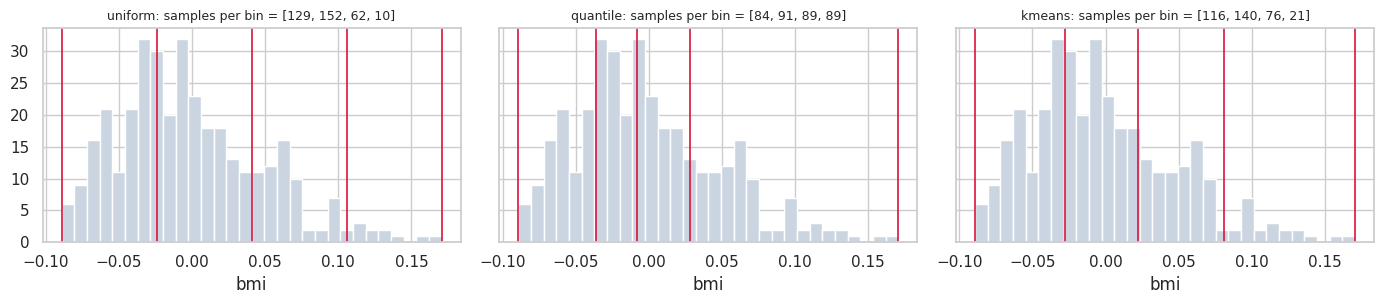

In [37]:
from sklearn.preprocessing import KBinsDiscretizer

feature = Xd_tr[["bmi"]]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.2), sharey=True)
for ax, strat in zip(axes, ["uniform", "quantile", "kmeans"]):
    kb = KBinsDiscretizer(n_bins=4, encode="ordinal", strategy=strat).fit(feature)
    edges = kb.bin_edges_[0]
    counts = np.bincount(kb.transform(feature).ravel().astype(int))
    ax.hist(feature["bmi"], bins=30, color="#cbd5e1")
    for e in edges:
        ax.axvline(e, color="crimson", lw=1.2)
    ax.set_title(f"{strat}: samples per bin = {counts.tolist()}", fontsize=9)
    ax.set_xlabel("bmi")
plt.tight_layout(); plt.show()

The red lines are the learned bin edges. `uniform` creates bins of equal width but very unequal populations (sparse tails), `quantile` equalises the populations, and `kmeans` adapts the edges to the data's clusters. Binning can help linear models capture non-linearities and reduces the influence of outliers, at the cost of discarding within-bin information.

### 6.3 `FunctionTransformer`: log transforms for skewed data

Right-skewed variables (income, counts, prices) often behave better after a $\log(1+x)$ transform, which compresses large values. `FunctionTransformer` wraps any function as a transformer so it can sit in a pipeline.

Skewness before: 2.648  ->  after log1p: -0.062


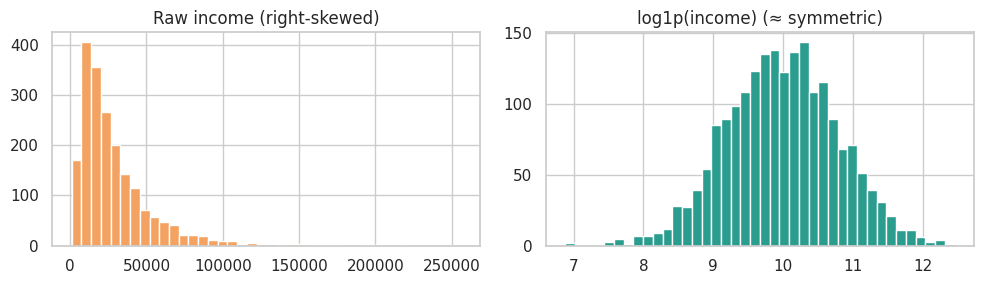

In [38]:
from sklearn.preprocessing import FunctionTransformer
from scipy.stats import skew

r = np.random.default_rng(0)
income = r.lognormal(mean=10, sigma=0.8, size=2000).reshape(-1, 1)

log_tf = FunctionTransformer(np.log1p, inverse_func=np.expm1)
income_log = log_tf.fit_transform(income)

print(f"Skewness before: {skew(income.ravel()):.3f}  ->  after log1p: {skew(income_log.ravel()):.3f}")
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].hist(income, bins=40, color="#f4a261"); ax[0].set_title("Raw income (right-skewed)")
ax[1].hist(income_log, bins=40, color="#2a9d8f"); ax[1].set_title("log1p(income) (≈ symmetric)")
plt.tight_layout(); plt.show()

The transform removes most of the skewness (a perfectly symmetric distribution has skewness 0), which suits models that assume roughly symmetric inputs or residuals.

### 6.4 Feature selection

The idea: the best model is the one that performs well with the **fewest necessary features**. We try four approaches on the Diabetes data.

#### a) Filter: `VarianceThreshold` and `SelectKBest`

`VarianceThreshold` removes (near-)constant features. `SelectKBest` scores each feature against the target with a statistical test (here the univariate F-statistic for regression, `f_regression`) and keeps the top $k$.

In [39]:
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_regression

# VarianceThreshold: add an artificial constant column to show it being removed
Xd_const = Xd_tr.assign(constant=1.0)
vt = VarianceThreshold(threshold=0.0).fit(Xd_const)
print("Columns removed by VarianceThreshold:", list(Xd_const.columns[~vt.get_support()]))

# SelectKBest with the F-test
skb = SelectKBest(score_func=f_regression, k=5).fit(Xd_tr, yd_tr)
scores = pd.DataFrame({"F-score": skb.scores_, "p-value": skb.pvalues_, "selected": skb.get_support()}, index=Xd.columns)
scores.sort_values("F-score", ascending=False)

Columns removed by VarianceThreshold: ['constant']


,F-score,p-value,selected
bmi,183.7590,0.0000,True
s5,154.5608,0.0000,True
bp,99.3362,0.0000,True
s4,72.4780,0.0000,True
s3,65.5057,0.0000,True
s6,59.7626,0.0000,False
age,11.3699,0.0008,False
s1,10.0181,0.0017,False
s2,6.1608,0.0135,False
sex,1.8967,0.1693,False


Features such as `bmi`, `s5` (a blood-serum measurement) and `bp` have the largest F-scores and tiny p-values, so they carry the strongest *individual* linear relationship with the target. Note the limitation of filter methods: each feature is scored **in isolation**, so they cannot detect interactions or redundancy between features.

#### b) Wrapper: Recursive Feature Elimination (`RFE`)

RFE starts with all features, fits an estimator that exposes coefficients or importances, removes the **least important** feature, and repeats until the desired number remain. With `n_features_to_select=1` it produces a **complete ranking** (1 = the last survivor = most important). `RFECV` adds cross-validation to choose the number of features automatically.

In [40]:
from sklearn.feature_selection import RFE, RFECV

rfe = RFE(estimator=LinearRegression(), n_features_to_select=1).fit(Xd_tr, yd_tr)
ranking = pd.Series(rfe.ranking_, index=Xd.columns, name="RFE rank (1 = best)").sort_values()
print(ranking.to_string())

rfecv = RFECV(estimator=LinearRegression(), cv=5, scoring="neg_mean_squared_error").fit(Xd_tr, yd_tr)
print(f"\nRFECV chose {rfecv.n_features_} features:", list(Xd.columns[rfecv.support_]))

bmi     1
s5      2
bp      3
s1      4
s2      5
sex     6
s4      7
s3      8
s6      9
age    10

RFECV chose 6 features: ['sex', 'bmi', 'bp', 's1', 's2', 's5']


The ranking orders all ten features by when they were eliminated. `RFECV` automatically selected the number of features that minimised the cross-validated error, saving us from guessing $k$.

#### c) Embedded: `SelectFromModel`

`SelectFromModel` keeps the features whose importance (absolute coefficient for linear models, `feature_importances_` for trees) exceeds a threshold (here the mean importance). **Lasso** is a natural choice because its $L_1$ penalty drives unimportant coefficients exactly to zero (Chapter 5).

In [41]:
from sklearn.feature_selection import SelectFromModel
from sklearn.linear_model import Lasso
from sklearn.ensemble import RandomForestRegressor

sfm_lasso = SelectFromModel(Lasso(alpha=1.0), threshold="mean").fit(Xd_tr, yd_tr)
sfm_rf    = SelectFromModel(RandomForestRegressor(n_estimators=200, random_state=0), threshold="mean").fit(Xd_tr, yd_tr)

imp = pd.DataFrame({
    "Lasso |coef|":       np.abs(sfm_lasso.estimator_.coef_),
    "Lasso selected":     sfm_lasso.get_support(),
    "RF importance":      sfm_rf.estimator_.feature_importances_,
    "RF selected":        sfm_rf.get_support(),
}, index=Xd.columns)
imp.sort_values("RF importance", ascending=False)

,Lasso |coef|,Lasso selected,RF importance,RF selected
s5,260.6022,True,0.2933,True
bmi,362.2478,True,0.2893,True
bp,61.8850,False,0.1074,True
s6,0.0000,False,0.0663,False
age,0.0000,False,0.0596,False
s2,0.0000,False,0.0564,False
s3,0.0000,False,0.0499,False
s1,0.0000,False,0.0458,False
s4,0.0000,False,0.0220,False
sex,0.0000,False,0.0101,False


Different selectors can disagree, because they define "importance" differently (linear weight versus split-based importance). Convergent evidence from several methods (here, `bmi` and `s5` appear in every list) is more trustworthy than any single method.

#### d) Does selection actually help?

We compare cross-validated RMSE for a linear model using all features versus subsets chosen *inside the pipeline* (so selection is repeated on each training fold).

In [42]:
from sklearn.model_selection import KFold

cv5 = KFold(n_splits=5, shuffle=True, random_state=0)
setups = {
    "All 10 features":         make_pipeline(LinearRegression()),
    "SelectKBest (k=5)":       make_pipeline(SelectKBest(f_regression, k=5), LinearRegression()),
    "RFE (5 features)":        make_pipeline(RFE(LinearRegression(), n_features_to_select=5), LinearRegression()),
    "SelectFromModel (Lasso)": make_pipeline(SelectFromModel(Lasso(alpha=1.0), threshold="mean"), LinearRegression()),
}
rows = []
for name, est in setups.items():
    rmse = -cross_val_score(est, Xd, yd, cv=cv5, scoring="neg_root_mean_squared_error")
    rows.append({"pipeline": name, "CV RMSE": rmse.mean(), "std": rmse.std()})
pd.DataFrame(rows).set_index("pipeline")

,CV RMSE,std
pipeline,,
All 10 features,54.5272,2.0942
SelectKBest (k=5),55.8777,1.8453
RFE (5 features),55.2365,2.0925
SelectFromModel (Lasso),56.9167,2.4864


Models with only five features (and even the Lasso selector, which keeps just two) reach an error within a few percent of the full model, which means the simpler models are almost as accurate and much easier to explain, as the "simplicity is favoured" principle suggests. On this small, clean dataset feature selection does not *improve* accuracy; its value lies in simplicity, speed and robustness, and it usually matters much more when there are hundreds of features and little data.

### 6.5 Hands-on workflow
1. Understand the dataset and identify opportunities for new features.
2. Create features with transformations or domain knowledge.
3. Apply selection (`RFE`, `SelectFromModel`, ...) to retain the informative ones.
4. Compare models trained with the original and engineered features.

## 7. Decision Guide: Which Transformation Should I Use?

The book summarises the choices in a decision diagram (Figure 2.17). The same logic as a table:

| Situation | Recommended step | Notes |
|:----------|:-----------------|:------|
| Missing values, $<5\%$ | `SimpleImputer(mean/median)` | Median if skewed |
| Missing values, 5-10%, numeric, correlated columns | `KNNImputer` or `IterativeImputer` | Tune $k$ / check cost |
| Missing values, $>10\%$ in one column | Drop the column or use domain-specific methods | Or add a missing indicator |
| Tree-based model (RF, gradient boosting) | May skip imputation/scaling | Native NaN support in many trees |
| Outliers present, scale-sensitive model | `RobustScaler` or clip, then scale | Investigate before deleting |
| Roughly Gaussian features, linear/SVM/PCA | `StandardScaler` | Default choice |
| Bounded inputs needed (NN, pixels) | `MinMaxScaler` | Sensitive to outliers |
| Direction matters (text, cosine) | `Normalizer` | Row-wise scaling |
| Nominal categories, low cardinality | `OneHotEncoder` | `handle_unknown="ignore"` |
| Ordinal categories | `OrdinalEncoder` with explicit order | |
| Nominal, high cardinality | `TargetEncoder`, `min_frequency` or hashing | |
| Target labels as text | `LabelEncoder` (targets only) | |
| Non-linear relationships with a linear model | `PolynomialFeatures`, `KBinsDiscretizer`, splines | Combine with regularisation |
| Skewed positive variable | `FunctionTransformer(np.log1p)` | |
| Many features, few samples | Feature selection / dimensionality reduction | Chapter 3 |
| Mixed column types | `ColumnTransformer` | Always inside a `Pipeline` |

## 8. Practical Exercise: A Comprehensive Pipeline on California Housing

We now put everything together. The **California Housing** dataset (from the 1990 census) has 20,640 block groups and 8 numeric features; the target is the median house value in units of \$100,000.

**Task** (from the book):
1. Load the California Housing dataset.
2. Split the data.
3. Create a pipeline with **at least three steps**, with an estimator last.
4. Fit the pipeline.
5. Evaluate it on the test data.

The cell below downloads the dataset through scikit-learn. If no internet connection is available (for example in a sandbox), it falls back to a **synthetic stand-in with the same column names**, and prints a clear message. Re-run the notebook on a machine with internet access (such as Google Colab) to use the real data.

In [43]:
try:
    from sklearn.datasets import fetch_california_housing
    housing = fetch_california_housing(as_frame=True)
    X_cal, y_cal = housing.data.copy(), housing.target.copy()
    DATA_SOURCE = "REAL California Housing dataset (downloaded by scikit-learn)"
except Exception as exc:                       # offline fallback with the same schema
    r = np.random.default_rng(42)
    n = 20640
    X_cal = pd.DataFrame({
        "MedInc":     r.lognormal(1.2, 0.5, n).clip(0.5, 15),
        "HouseAge":   r.integers(1, 53, n).astype(float),
        "AveRooms":   r.lognormal(1.7, 0.3, n).clip(1, 20),
        "AveBedrms":  r.lognormal(0.0, 0.15, n).clip(0.5, 5),
        "Population": r.lognormal(7.0, 0.7, n).clip(3, 35000),
        "AveOccup":   r.lognormal(1.0, 0.3, n).clip(0.7, 20),
        "Latitude":   r.uniform(32.5, 42.0, n),
        "Longitude":  r.uniform(-124.3, -114.3, n),
    })
    signal = (0.45 * X_cal["MedInc"] + 0.01 * X_cal["HouseAge"] - 0.15 * np.log(X_cal["AveOccup"])
              - 0.08 * (X_cal["Latitude"] - 37) ** 2 / 5 + 0.02 * X_cal["AveRooms"])
    y_cal = pd.Series((signal + r.normal(0, 0.35, n)).clip(0.15, 5.0), name="MedHouseVal")
    DATA_SOURCE = "SYNTHETIC offline stand-in with the same columns (offline sandbox; re-run with internet for the real data)"

print("Data source:", DATA_SOURCE)
print("Shape:", X_cal.shape)
X_cal.describe().T[["mean", "std", "min", "max"]]

Data source: SYNTHETIC offline stand-in with the same columns (offline sandbox; re-run with internet for the real data)
Shape: (20640, 8)


,mean,std,min,max
MedInc,3.7754,2.0080,0.5000,15.0000
HouseAge,26.5076,14.9393,1.0000,52.0000
AveRooms,5.6995,1.7504,1.5264,20.0000
AveBedrms,1.0112,0.1536,0.5565,1.8735
Population,1394.5478,1121.0938,72.1178,25712.2309
AveOccup,2.8376,0.8794,0.8631,9.1479
Latitude,37.2346,2.7350,32.5004,41.9991
Longitude,-119.2942,2.8944,-124.2997,-114.3003


The real dataset has no missing values, but real-world tables usually do. To exercise the imputer step realistically, we **randomly blank 3% of the entries** of the feature table (this is an artificial modification for the exercise). We then split the data into training and test sets *before* any preprocessing.

In [44]:
r = np.random.default_rng(0)
X_cal_missing = X_cal.copy()
mask = r.random(X_cal_missing.shape) < 0.03
X_cal_missing = X_cal_missing.mask(mask)
print(f"Artificially missing entries: {X_cal_missing.isna().sum().sum()} ({X_cal_missing.isna().sum().sum() / X_cal_missing.size:.1%})")

X_tr, X_te, y_tr, y_te = train_test_split(X_cal_missing, y_cal, test_size=0.2, random_state=2024)
print("Train:", X_tr.shape, "| Test:", X_te.shape)

Artificially missing entries: 4905 (3.0%)
Train: (16512, 8) | Test: (4128, 8)


### 8.1 Baseline pipeline

First a simple baseline with three steps: impute, scale, and fit a linear model.

In [45]:
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

def report(name, model, X_te=X_te, y_te=y_te):
    pred = model.predict(X_te)
    return {"model": name,
            "RMSE": np.sqrt(mean_squared_error(y_te, pred)),
            "MAE": mean_absolute_error(y_te, pred),
            "R^2": r2_score(y_te, pred)}

baseline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler",  StandardScaler()),
    ("model",   LinearRegression()),
])
baseline.fit(X_tr, y_tr)
results = [report("Baseline: impute + scale + OLS", baseline)]
pd.DataFrame(results).set_index("model")

,RMSE,MAE,R^2
model,,,
Baseline: impute + scale + OLS,0.4069,0.3089,0.8122


The baseline satisfies the book's requirement of three steps with an estimator last. How well did it do? We evaluate with three complementary metrics:

- **RMSE**: $\sqrt{\frac{1}{n}\sum(y_i-\hat y_i)^2}$, in the units of the target; penalises large errors.
- **MAE**: $\frac{1}{n}\sum|y_i-\hat y_i|$, the average absolute error; less sensitive to outliers.
- **$R^2$**: fraction of variance explained.

### 8.2 A richer pipeline with feature engineering and selection

We now add what we learned: a log transform for skewed count-like columns, polynomial interactions, embedded feature selection with Lasso, and a regularised Ridge model as the final estimator.

In [46]:
skewed = ["AveRooms", "AveBedrms", "Population", "AveOccup"]
other = [c for c in X_cal.columns if c not in skewed]

log_cols = ColumnTransformer(
    [("log", FunctionTransformer(np.log1p), skewed)],
    remainder="passthrough",
    verbose_feature_names_out=False,
).set_output(transform="pandas")

from sklearn.linear_model import Ridge

engineered = Pipeline([
    ("imputer", SimpleImputer(strategy="median").set_output(transform="pandas")),   # keep column names for the next step
    ("log",     log_cols),
    ("scaler",  StandardScaler()),
    ("poly",    PolynomialFeatures(degree=2, include_bias=False)),
    ("select",  SelectFromModel(Lasso(alpha=0.005, max_iter=5000), threshold="mean")),
    ("model",   Ridge(alpha=1.0)),
])
engineered.fit(X_tr, y_tr)

n_poly = engineered.named_steps["poly"].n_output_features_
n_sel = engineered.named_steps["select"].get_support().sum()
print(f"Polynomial step produced {n_poly} features; the Lasso selector kept {n_sel}.")

results.append(report("Engineered: impute + log + poly + select + Ridge", engineered))
pd.DataFrame(results).set_index("model")

Polynomial step produced 44 features; the Lasso selector kept 5.


,RMSE,MAE,R^2
model,,,
Baseline: impute + scale + OLS,0.4069,0.3089,0.8122
Engineered: impute + log + poly + select + Ridge,0.3898,0.2966,0.8277


The engineered pipeline captures non-linear structure and interactions that a plain linear model cannot, and it should reduce the error relative to the baseline (compare the table above). The selector keeps only part of the polynomial features, which keeps the final model compact.

### 8.3 Tuning the pipeline with `GridSearchCV`

Rather than fixing the polynomial degree and the penalty, we search over them with 3-fold cross-validation on the training set.

In [47]:
param_grid = {
    "poly__degree": [1, 2, 3],
    "select__estimator__alpha": [0.001, 0.005, 0.02],
    "model__alpha": [0.1, 1.0, 10.0],
}
gs = GridSearchCV(engineered, param_grid, cv=3, scoring="neg_root_mean_squared_error", n_jobs=-1)
gs.fit(X_tr, y_tr)

print("Best parameters:", gs.best_params_)
print(f"Best CV RMSE: {-gs.best_score_:.4f}")
results.append(report("Tuned engineered pipeline (GridSearchCV)", gs.best_estimator_))
final_table = pd.DataFrame(results).set_index("model")
final_table

Best parameters: {'model__alpha': 0.1, 'poly__degree': 3, 'select__estimator__alpha': 0.001}
Best CV RMSE: 0.3804


,RMSE,MAE,R^2
model,,,
Baseline: impute + scale + OLS,0.4069,0.3089,0.8122
Engineered: impute + log + poly + select + Ridge,0.3898,0.2966,0.8277
Tuned engineered pipeline (GridSearchCV),0.3852,0.2920,0.8317


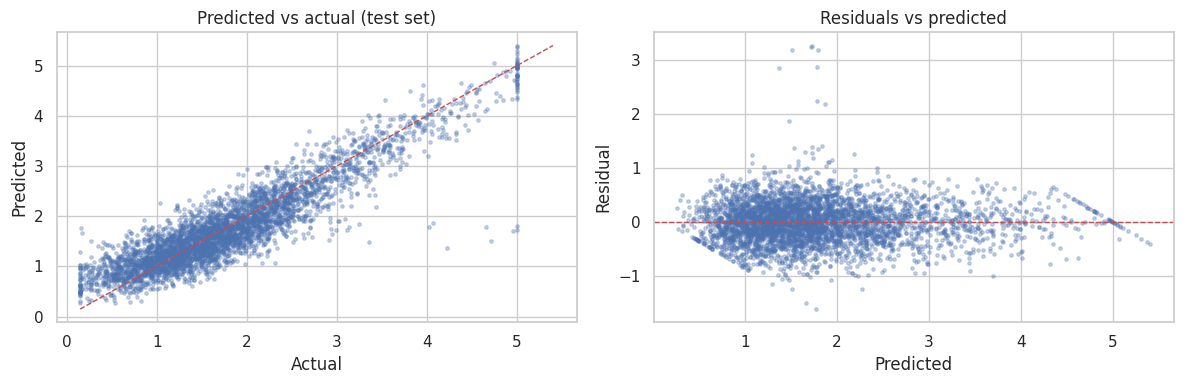

In [48]:
best = gs.best_estimator_
pred = best.predict(X_te)
resid = y_te - pred

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(y_te, pred, s=6, alpha=0.3)
lims = [min(y_te.min(), pred.min()), max(y_te.max(), pred.max())]
ax[0].plot(lims, lims, "r--", lw=1)
ax[0].set_xlabel("Actual"); ax[0].set_ylabel("Predicted"); ax[0].set_title("Predicted vs actual (test set)")
ax[1].scatter(pred, resid, s=6, alpha=0.3)
ax[1].axhline(0, color="r", ls="--", lw=1)
ax[1].set_xlabel("Predicted"); ax[1].set_ylabel("Residual"); ax[1].set_title("Residuals vs predicted")
plt.tight_layout(); plt.show()

Two diagnostic plots complete the evaluation:

- **Predicted vs actual**: points should hug the dashed diagonal. Systematic bending reveals bias.
- **Residuals vs predicted**: residuals should scatter randomly around zero. A funnel shape (heteroscedasticity) or curve means the model misses structure.

Remember that the **data source printed above** determines the exact numbers: with the real dataset you can expect the error values to differ from a synthetic stand-in, but the *workflow and the comparisons between pipelines* are what this exercise is about.

## Summary

- **Data quality drives model quality.** We demonstrated how missing values, outliers and unscaled features damage models, using quick experiments.
- **Imputation** is estimation. A controlled experiment showed that simple statistics suffice for independent features, whereas `KNNImputer` and `IterativeImputer` win when features are correlated. Some tree models handle `NaN` natively.
- **Scaling** matters for distance-based and gradient-based models (KNN, SVM, logistic regression) but not for trees. `RobustScaler` is the safe choice with outliers; `Normalizer` is a row-wise operation, not a feature scaler.
- **Encoding** must match the variable type: one-hot for nominal, ordinal with explicit order for ordinal, target encoding for high cardinality, and `LabelEncoder` only for targets. Wrong encodings can destroy a linear model's performance.
- **Pipelines** guarantee that preprocessing is fitted on training data only and let you tune preprocessing and model hyperparameters together.
- **Feature engineering** (polynomial terms, binning, log transforms) and **feature selection** (filter, wrapper, embedded) can simplify and improve models.

In **Chapter 3** we go one step further: **dimensionality reduction** (PCA, LDA, t-SNE) compresses many features into a few informative ones.